# Эксперименты и анализ ошибок

In [2]:
from pathlib import Path
import inspect
import json
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from lawankz.rk2_week4 import (
    build_experiment_specs,
    run_week4_analysis,
    stratified_subset_indices,
)

RESULTS_DIR = PROJECT_ROOT / "results" / "rk2_week4"
summary = json.loads((RESULTS_DIR / "summary.json").read_text(encoding="utf-8"))
summary

{'week': 4,
 'task': 'Экспериментальное исследование и анализ ошибок fine-tuned RuBERT',
 'article_count': 306,
 'fit_count': 183,
 'validation_count': 46,
 'test_count': 77,
 'controlled_run_count': 5,
 'controlled_epochs': 2,
 'learning_rates': [1e-05, 3e-05, 5e-05],
 'data_fractions': [0.5, 0.75, 1.0],
 'week3_baseline': {'accuracy': 0.8571,
  'precision_macro': 0.8519,
  'recall_macro': 0.858,
  'f1_macro': 0.8527},
 'selected_by_validation': {'experiment_id': 'lr_5em05_data_100',
  'source': 'week4_controlled',
  'data_fraction': 1.0,
  'train_articles': 183,
  'learning_rate': 5e-05,
  'epochs': 2,
  'best_epoch': 2,
  'validation_f1_macro': 0.8402,
  'runtime_seconds': 69.43,
  'accuracy': 0.8571,
  'precision_macro': 0.8566,
  'recall_macro': 0.8796,
  'f1_macro': 0.8666},
 'error_sample_size': 10,
 'error_causes': {'дисбаланс классов': 1,
  'короткий общий контекст': 4,
  'междокументные ссылки': 1,
  'неоднозначность контекста': 4},
 'test_isolation': 'Одинаковый test использ

## 1. План контролируемых экспериментов

In [3]:
pd.DataFrame(build_experiment_specs())

,experiment_id,learning_rate,data_fraction
0,lr_1em05_data_100,0.00001,1.00
1,lr_3em05_data_100,0.00003,1.00
2,lr_5em05_data_100,0.00005,1.00
3,lr_3em05_data_50,0.00003,0.50
4,lr_3em05_data_75,0.00003,0.75


In [4]:
print(inspect.getsource(stratified_subset_indices))

def stratified_subset_indices(
    articles: list[dict],
    indices: np.ndarray,
    fraction: float,
    *,
    seed: int = SEED,
) -> np.ndarray:
    """Взять воспроизводимую долю каждого класса из обучающей выборки."""
    if not 0 < fraction <= 1:
        raise ValueError("Доля обучающих данных должна находиться в интервале (0, 1]")
    if fraction == 1:
        return np.sort(np.asarray(indices, dtype=int))

    rng = np.random.default_rng(seed)
    groups: dict[str, list[int]] = {}
    for index in indices:
        label = articles[int(index)]["document_id"]
        groups.setdefault(label, []).append(int(index))

    selected: list[int] = []
    for label in sorted(groups):
        candidates = np.asarray(groups[label], dtype=int)
        rng.shuffle(candidates)
        count = max(1, int(round(len(candidates) * fraction)))
        selected.extend(candidates[:count].tolist())
    return np.asarray(sorted(selected), dtype=int)



## 2. Код полного запуска

In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    summary = run_week4_analysis(
        PROJECT_ROOT / "results" / "weeks_1_4" / "processed_articles.jsonl",
        PROJECT_ROOT / "results" / "rk2_week3" / "summary.json",
        PROJECT_ROOT / "results" / "rk2_week3" / "test_predictions.csv",
        RESULTS_DIR,
    )
else:
    print("Загружены сохранённые результаты пяти выполненных запусков.")

Загружены сохранённые результаты пяти выполненных запусков.


## 3. Сводная таблица Accuracy, Precision, Recall и F1

In [6]:
results = pd.read_csv(RESULTS_DIR / "experiment_results.csv")
results

,experiment_id,source,data_fraction,train_articles,learning_rate,epochs,best_epoch,validation_f1_macro,runtime_seconds,accuracy,precision_macro,recall_macro,f1_macro
0,week3_baseline,week3_baseline,1.00,183,0.00003,4,3,0.8755,NaN,0.8571,0.8519,0.8580,0.8527
1,lr_1em05_data_100,week4_controlled,1.00,183,0.00001,2,2,0.3804,67.61,0.4286,0.4537,0.4990,0.4089
2,lr_3em05_data_100,week4_controlled,1.00,183,0.00003,2,2,0.6277,65.94,0.7273,0.7906,0.8056,0.7780
3,lr_5em05_data_100,week4_controlled,1.00,183,0.00005,2,2,0.8402,69.43,0.8571,0.8566,0.8796,0.8666
4,lr_3em05_data_50,week4_controlled,0.50,91,0.00003,2,2,0.4528,45.15,0.5455,0.5333,0.5718,0.5139
5,lr_3em05_data_75,week4_controlled,0.75,136,0.00003,2,2,0.5123,51.74,0.6104,0.6797,0.7384,0.6235


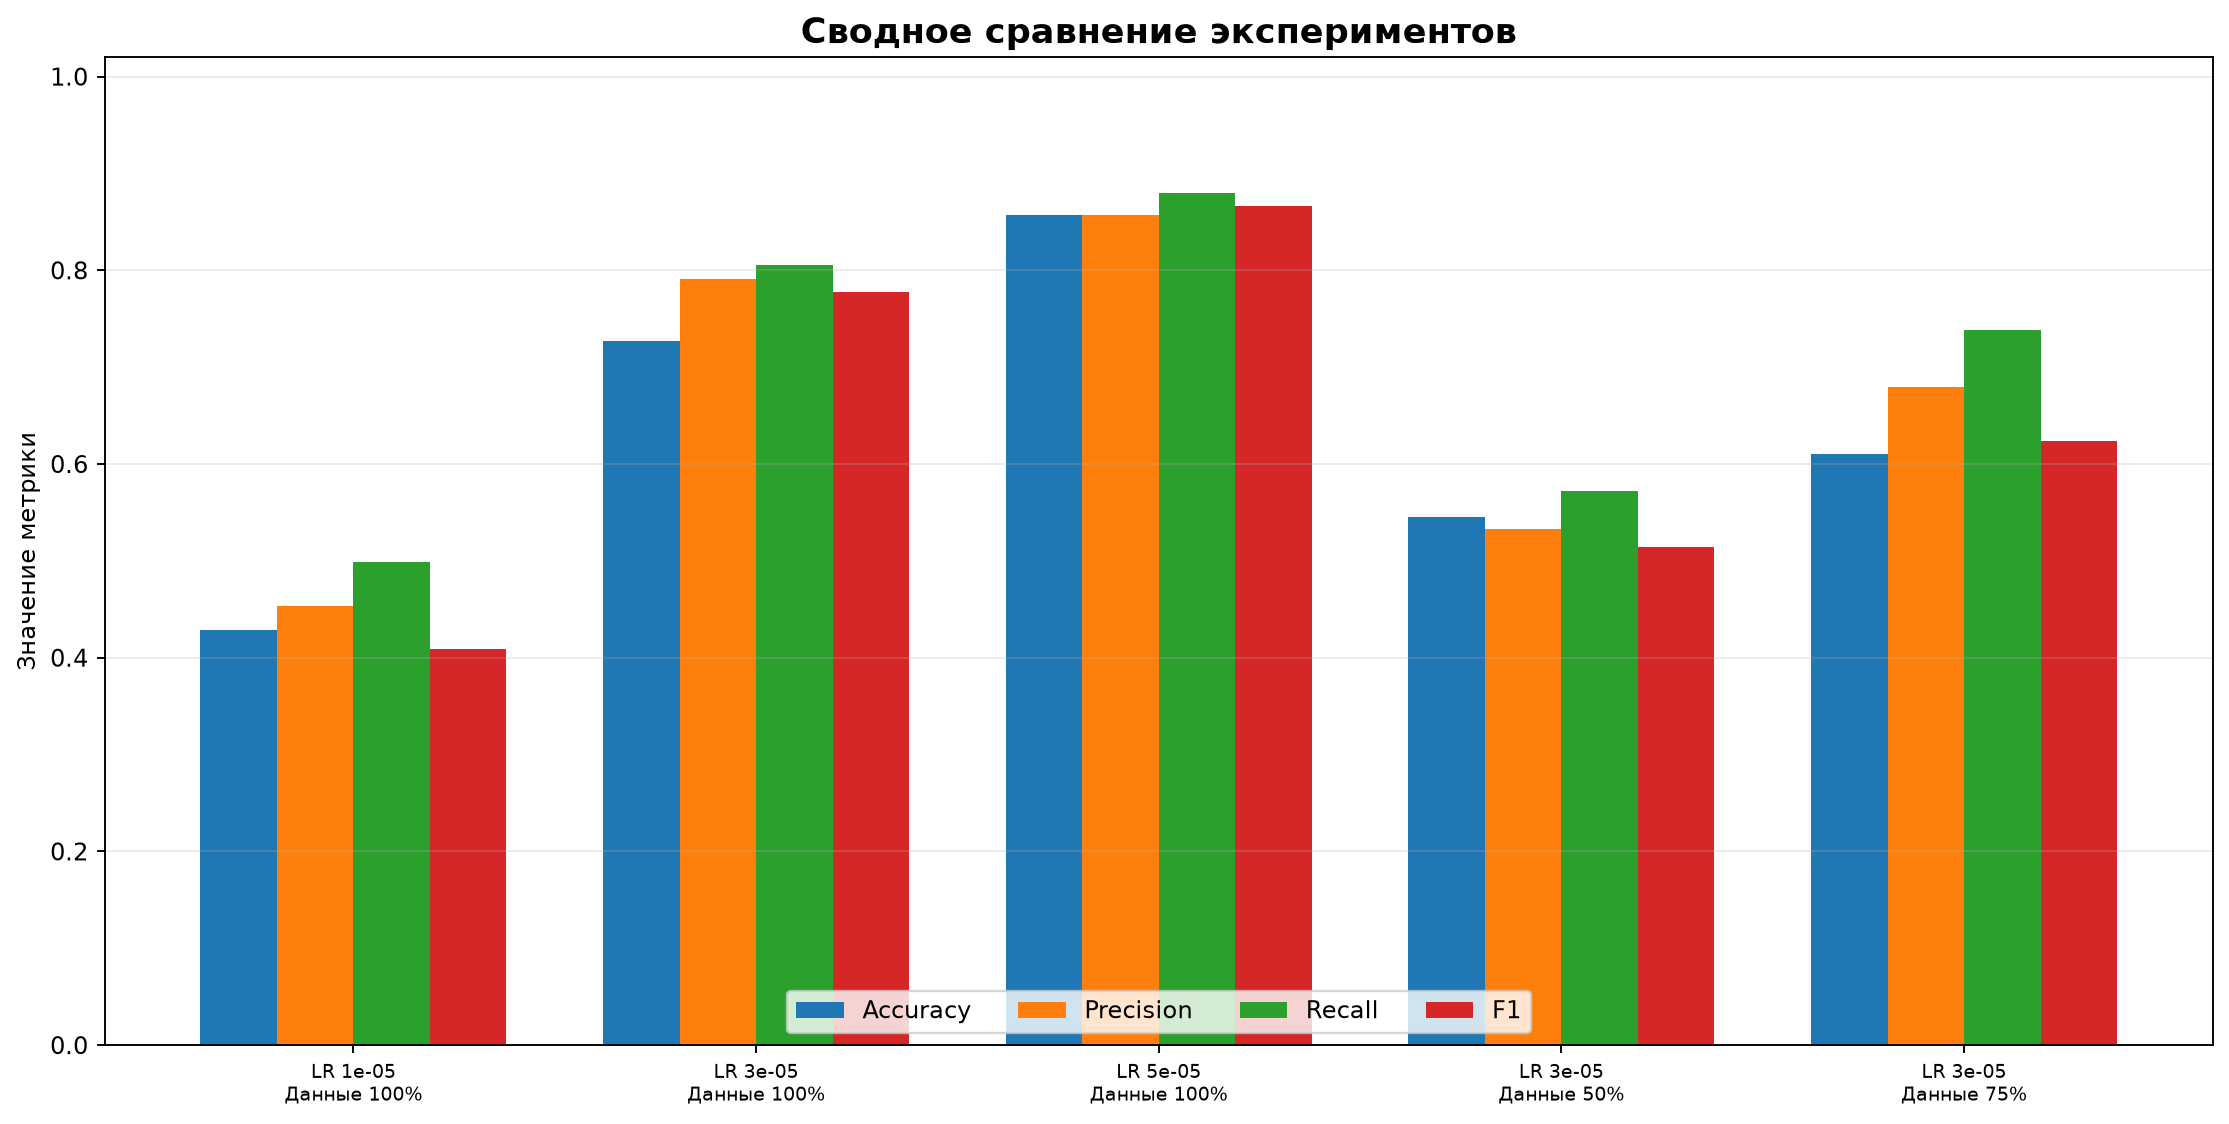

In [7]:
display(Image(filename=str(RESULTS_DIR / "experiment_metrics.png"), width=1050))

## 4. Динамика метрик

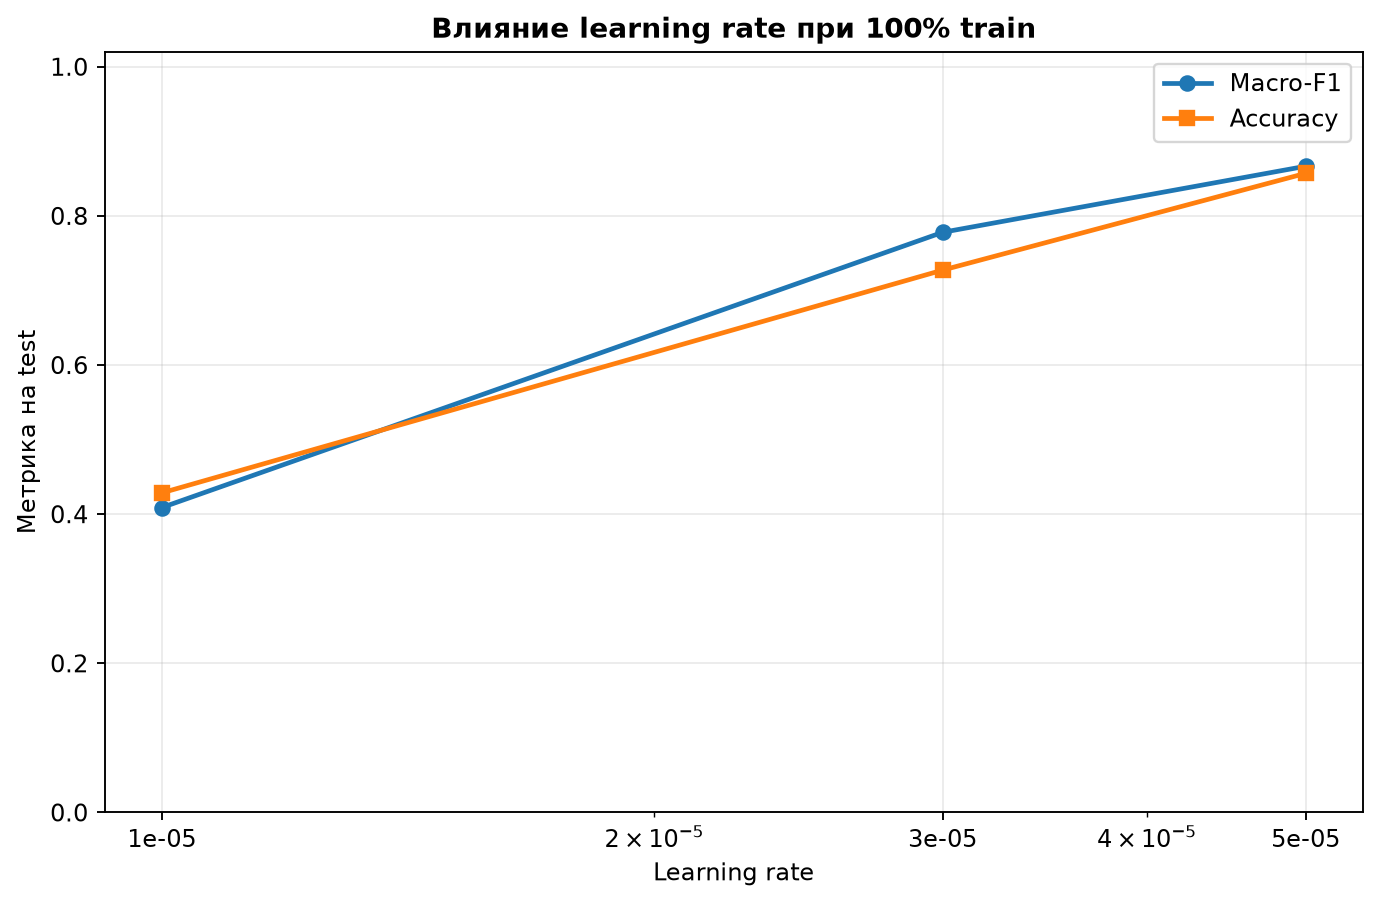

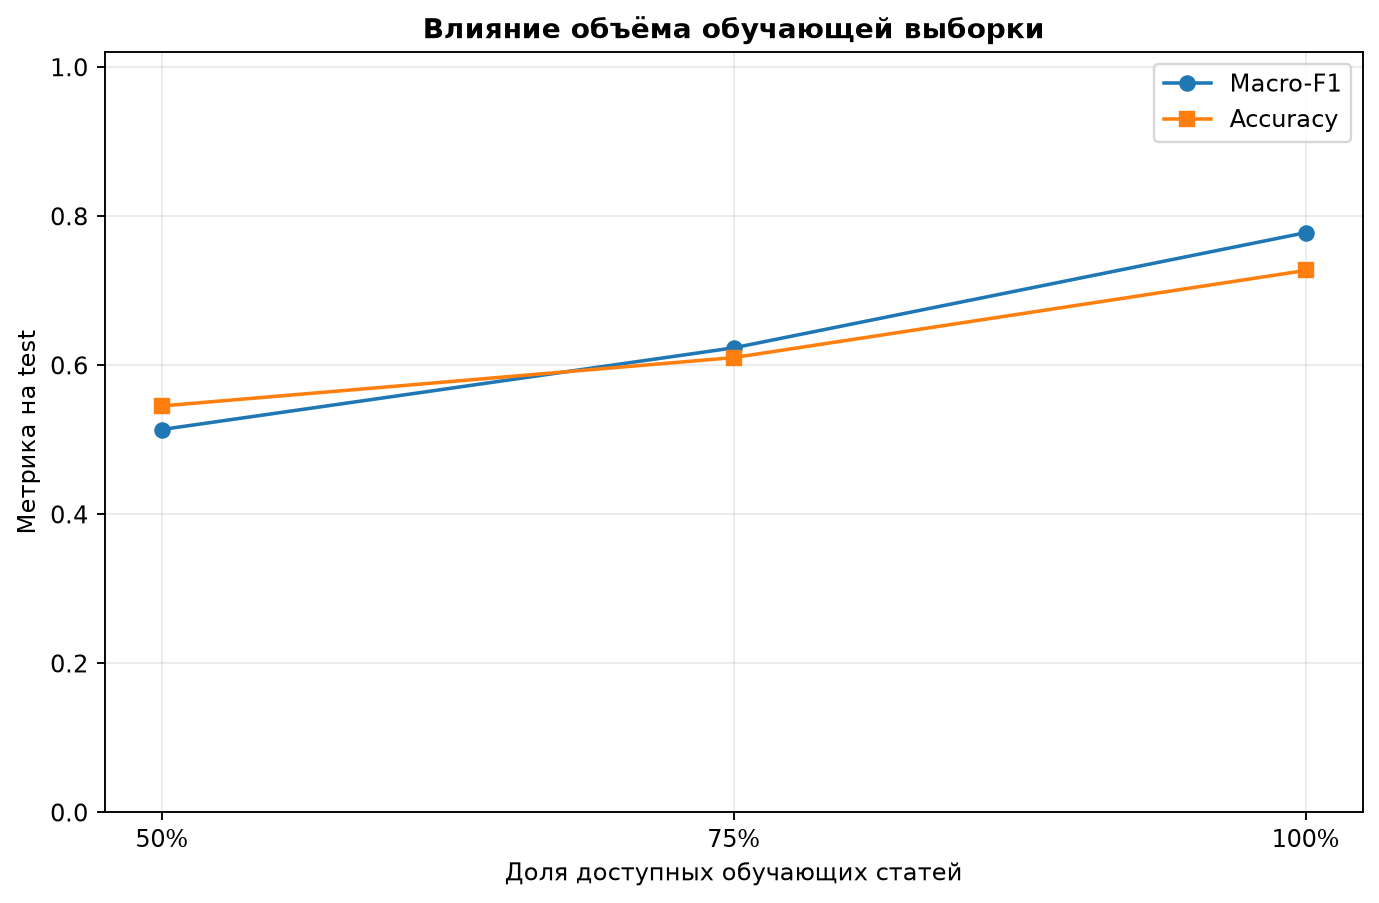

In [8]:
display(Image(filename=str(RESULTS_DIR / "learning_rate_dynamics.png"), width=700))
display(Image(filename=str(RESULTS_DIR / "data_size_dynamics.png"), width=700))

## 5. Десять ошибок базовой модели

In [9]:
errors = pd.read_csv(RESULTS_DIR / "error_analysis_10.csv")
errors[[
    "article_id", "true_label_ru", "predicted_label_ru", "confidence",
    "hypothesized_cause", "cause_explanation", "text_preview",
]]

,article_id,true_label_ru,predicted_label_ru,confidence,hypothesized_cause,cause_explanation,text_preview
0,cybersecurity:52,Кибербезопасность,Цифровой кодекс,0.2521,короткий общий контекст,в статье только 50 слов,1. Журналирование цифровых событий обеспечивае...
1,digital_code:99,Цифровой кодекс,Кибербезопасность,0.2463,короткий общий контекст,в статье только 72 слов,1. Испытания цифровых объектов на соответствие...
2,cybersecurity:79,Кибербезопасность,Цифровой кодекс,0.2410,короткий общий контекст,в статье только 39 слов,"Собственники и владельцы цифровых систем, соде..."
3,cybersecurity:75,Кибербезопасность,Цифровой кодекс,0.2407,междокументные ссылки,текст активно ссылается на другие нормы и кодекс,1. Защитой цифровых объектов является реализац...
4,digital_code:92,Цифровой кодекс,Кибербезопасность,0.2342,неоднозначность контекста,лексика статьи подходит нескольким тематически...,"Цифровые объекты, предназначенные для реализац..."
5,digital_code:27,Цифровой кодекс,Кибербезопасность,0.2290,неоднозначность контекста,лексика статьи подходит нескольким тематически...,1. Центром обработки данных признается объект ...
6,digital_code:70,Цифровой кодекс,Искусственный интеллект,0.2173,короткий общий контекст,в статье только 36 слов,1. Смарт-города и смарт-регионы – города и рег...
7,digital_code:72,Цифровой кодекс,Кибербезопасность,0.2140,неоднозначность контекста,лексика статьи подходит нескольким тематически...,1. Архитектурно-координационный центр – юридич...
8,cybersecurity:86,Кибербезопасность,Доступ к информации,0.2133,неоднозначность контекста,лексика статьи подходит нескольким тематически...,1. Профилактический контроль без посещения суб...
9,access_to_information:22,Доступ к информации,Связь,0.2011,дисбаланс классов,истинный класс представлен в train слабее меди...,1. Государство обеспечивает лицам с инвалиднос...


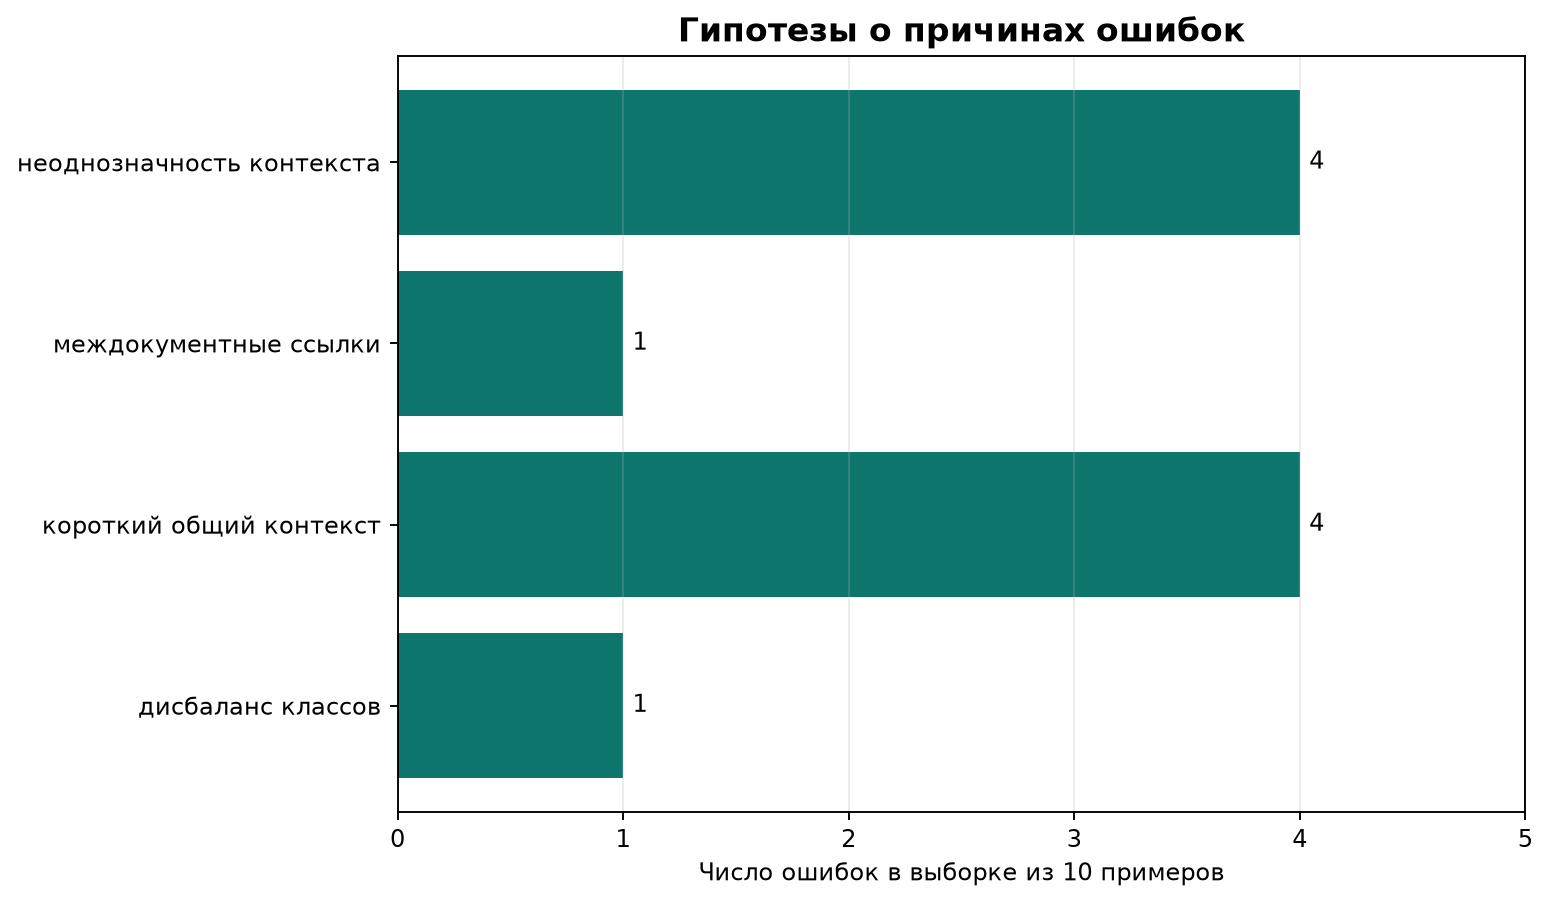

In [10]:
display(Image(filename=str(RESULTS_DIR / "error_causes.png"), width=800))